# TunSign : Reconnaissance de la Langue des Signes Tunisienne (TSL)
**Projet de Machine Learning supervisé**  
*Conforme au cycle de vie en 7 étapes du cours de Machine Learning de Mme Arfaoui.*

---

## 1 Compréhension du problème métier

### Ce que nous faisons :
Dans cette première étape, nous formalisons le besoin métier en un problème précis et mesurable de Machine Learning.

### Pourquoi nous le faisons (selon le cours) :
Comme l'enseigne Mme Arfaoui (*Séance 1, diapositive 31*), tout projet de Machine Learning commence impérativement par traduire un besoin métier général en une tâche d'apprentissage claire, en précisant les données nécessaires et les critères d'évaluation (KPI).

### Les 4 questions fondamentales du cours :
1. **Quel est l'objectif métier précis ?**  
   Permettre aux personnes sourdes et malentendantes en Tunisie de communiquer plus facilement avec les personnes entendantes, en traduisant automatiquement les gestes de la Langue des Signes Tunisienne (TSL / TunSL) en texte écrit en temps réel (via webcam ou images).
2. **Quel type de tâche de Machine Learning cela implique-t-il ?**  
   Il s'agit d'un problème d'**apprentissage supervisé** (*Supervised Learning*), plus particulièrement d'une **classification multiclasse** comportant 57 classes discrètes (57 signes/mots distincts).
3. **Quelles données sont réellement disponibles ?**  
   Nous disposons du jeu de données académique *First-ever Tunisian Sign Language Dataset* (SUP'COM / Association Tunisienne des Sourds), constitué de 4 423 images réparties en 57 signes et 5 thématiques (Demandes, Destinations, Famille, Jours, Transport).
4. **Comment mesurera-t-on le succès (KPI / Métriques) ?**  
   - **Accuracy globale** : pourcentage global de prédictions correctes.
   - **Macro-F1 score** : métrique prioritaire pour évaluer équitablement toutes les classes, compte tenu du déséquilibre naturel des effectifs par signe.
   - **Matrice de confusion** : pour analyser les erreurs spécifiques entre signes visuellement proches.
   - **Temps d'inférence** : traitement rapide (< 50 millisecondes par image) pour garantir une utilisation fluide sur flux vidéo webcam.

## 2 Collecte des données

### Ce que nous faisons :
Nous explorons les dossiers du jeu de données brut, recensons chaque image avec son étiquette (signe) et sa catégorie thématique, puis nous construisons notre premier tableau récapitulatif (*DataFrame*).

### Pourquoi nous le faisons (selon le cours) :
D'après la *Séance 1 (diapositive 32)* et la *Séance Préparation des données (diapositives 5-6)*, la collecte consiste à rassembler les données brutes disponibles pour construire la structure tabulaire initiale (matrice d'observations) qui servira de base à l'exploration et aux étapes suivantes.

### Outils utilisés :
- `pathlib.Path` : manipulation robuste des chemins de fichiers.
- `pandas` : création et manipulation de la structure de données tabulaire (*DataFrame*).

In [1]:
# Importation de pathlib pour manipuler facilement les chemins de fichiers
from pathlib import Path

# Importation de pandas pour structurer nos données sous forme de tableau (DataFrame)
import pandas as pd

# Définition du chemin vers le dossier racine contenant les données brutes
chemin_donnees_brutes = Path('../data/raw')

# Localisation automatique du dossier 'Data' contenant les sous-dossiers thématiques
dossier_data = list(chemin_donnees_brutes.rglob('Data'))[0]

# Initialisation d'une liste vide pour enregistrer les informations de chaque image
donnees_collectees = []

# Parcours de toutes les images ayant l'extension .jpg dans l'arborescence
for chemin_image in sorted(dossier_data.rglob('*.jpg')):
    # Le dossier parent direct correspond au nom de la classe (le signe gestuel)
    nom_classe = chemin_image.parent.name
    # Le dossier supérieur correspond à la catégorie thématique (Demandes, Famille, etc.)
    nom_categorie = chemin_image.parent.parent.name
    # On ajoute un dictionnaire contenant les informations de l'observation
    donnees_collectees.append({
        'chemin_image': str(chemin_image),
        'categorie': nom_categorie,
        'classe': nom_classe
    })

# Création du DataFrame pandas à partir de la liste d'observations
df_images = pd.DataFrame(donnees_collectees)

# Affichage du nombre total d'images collectées
print(f"Nombre total d'images collectées : {len(df_images)}")
print(f"Nombre de catégories thématiques : {df_images['categorie'].nunique()}")
print(f"Nombre total de signes (classes) : {df_images['classe'].nunique()}")

# Affichage des 5 premières lignes du tableau pour vérification
df_images.head()

Nombre total d'images collectées : 4423
Nombre de catégories thématiques : 5
Nombre total de signes (classes) : 57


,chemin_image,categorie,classe
0,..\data\raw\First-ever-Tunisian-Sign-Language-...,Demandes,3aslema
1,..\data\raw\First-ever-Tunisian-Sign-Language-...,Demandes,3aslema
2,..\data\raw\First-ever-Tunisian-Sign-Language-...,Demandes,3aslema
3,..\data\raw\First-ever-Tunisian-Sign-Language-...,Demandes,3aslema
4,..\data\raw\First-ever-Tunisian-Sign-Language-...,Demandes,3aslema


## 3 Exploration et nettoyage (EDA)

### Ce que nous faisons :
Dans cette étape d'Analyse Exploratoire des Données (*Exploratory Data Analysis - EDA*), nous analysons en détail la structure de notre jeu de données : dimensions, types de données, valeurs manquantes, doublons, distribution des classes et détection des valeurs extrêmes (outliers).

### Pourquoi nous le faisons (selon le cours) :
Comme l'explique Mme Arfaoui (*Séance 1, diapositive 33* et *Séance Préparation des données, diapositives 10-25*), l'EDA est souvent l'étape la plus cruciale pour :
1. Comprendre la forme et la qualité des données avant toute modélisation.
2. Détecter d'éventuelles anomalies (valeurs manquantes, doublons).
3. Identifier le **déséquilibre des classes** (*class imbalance*) qui fausserait les métriques naïves comme l'accuracy.
4. Appliquer les méthodes formelles du cours (**IQR** et **Z-Score**) pour identifier les valeurs extrêmes/aberrantes (*outliers*).

### Outils utilisés :
- `pandas` : `shape`, `info()`, `describe()`, `isnull().sum()`, `duplicated().sum()`, `value_counts()`.
- `numpy` : calculs statistiques (moyenne, écart-type, Z-score).
- `matplotlib.pyplot` : visualisation graphique de la distribution des classes.

In [2]:
# Affichage des dimensions du tableau (nombre de lignes m, nombre de colonnes d)
print("Dimensions du tableau (lignes, colonnes) :", df_images.shape)

# Résumé complet de la structure : types des colonnes et mémoire utilisée
print("\n--- Informations générales (info) ---")
df_images.info()

# Statistiques descriptives pour les colonnes qualitatives (catégorielles)
print("\n--- Statistiques descriptives (describe include='all') ---")
print(df_images.describe(include='all'))

# Vérification de la présence de valeurs manquantes dans chaque colonne
print("\n--- Nombre de valeurs manquantes par colonne (isnull) ---")
print(df_images.isnull().sum())

# Vérification du nombre de lignes dupliquées (doublons)
print("\n--- Nombre de lignes dupliquées (duplicated) ---")
print(f"Total doublons : {df_images.duplicated().sum()}")

Dimensions du tableau (lignes, colonnes) : (4423, 3)

--- Informations générales (info) ---
<class 'pandas.DataFrame'>
RangeIndex: 4423 entries, 0 to 4422
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   chemin_image  4423 non-null   str  
 1   categorie     4423 non-null   str  
 2   classe        4423 non-null   str  
dtypes: str(3)
memory usage: 103.8 KB

--- Statistiques descriptives (describe include='all') ---
                                             chemin_image categorie classe
count                                                4423      4423   4423
unique                                               4423         5     57
top     ..\data\raw\First-ever-Tunisian-Sign-Language-...   Famille   bent
freq                                                    1      1748    224

--- Nombre de valeurs manquantes par colonne (isnull) ---
chemin_image    0
categorie       0
classe          0
dtype: int64

--- Nomb

--- Répartition par catégorie thématique ---
categorie
Famille         1748
Demandes        1400
Destinations     608
Jours            365
Transport        302
Name: count, dtype: int64

--- Statistiques sur les effectifs des classes ---
Nombre minimal d'images par classe : 15 (classe : mar7ba)
Nombre maximal d'images par classe : 224 (classe : bent)
Moyenne d'images par classe : 77.6
Médiane d'images par classe : 57.0


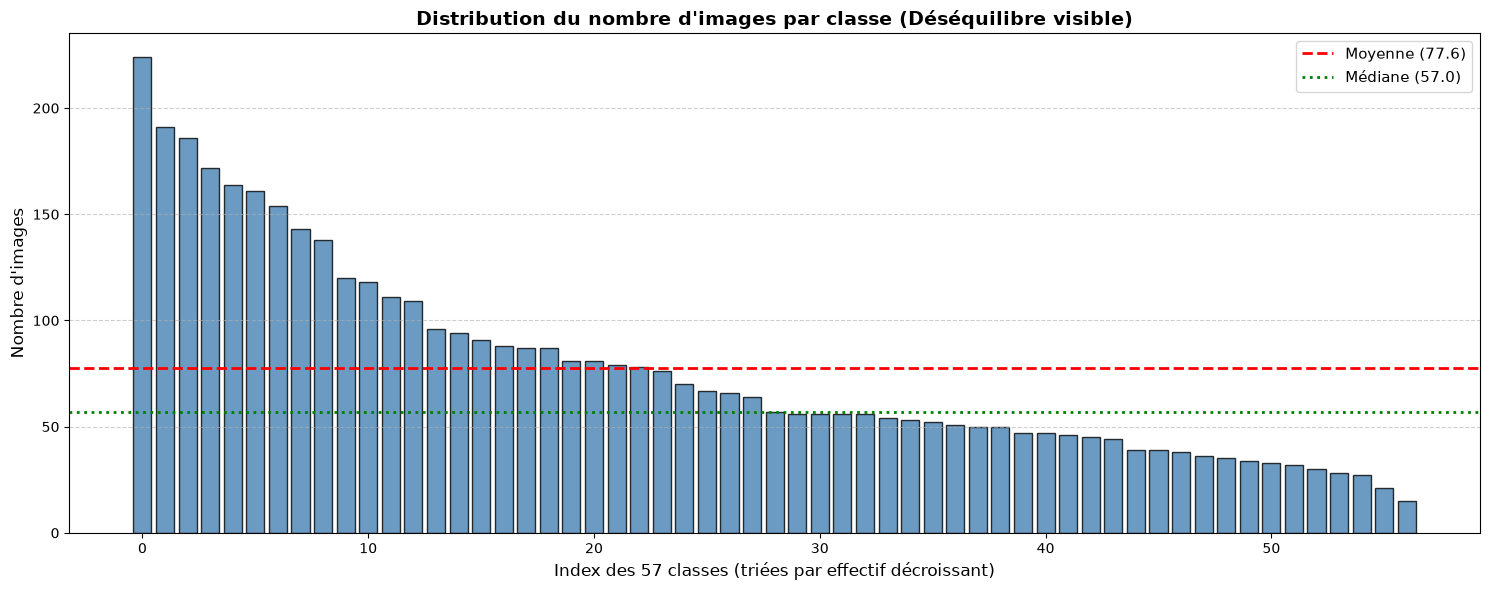

In [3]:
# Importation de matplotlib pour créer nos graphiques
import matplotlib.pyplot as plt

# Calcul du nombre d'images par catégorie thématique
repartition_categories = df_images['categorie'].value_counts()
print("--- Répartition par catégorie thématique ---")
print(repartition_categories)

# Calcul des effectifs d'images pour chacune des 57 classes (signes)
repartition_classes = df_images['classe'].value_counts()
print("\n--- Statistiques sur les effectifs des classes ---")
print(f"Nombre minimal d'images par classe : {repartition_classes.min()} (classe : {repartition_classes.idxmin()})")
print(f"Nombre maximal d'images par classe : {repartition_classes.max()} (classe : {repartition_classes.idxmax()})")
print(f"Moyenne d'images par classe : {repartition_classes.mean():.1f}")
print(f"Médiane d'images par classe : {repartition_classes.median():.1f}")

# Création d'une figure pour visualiser la distribution des classes
plt.figure(figsize=(15, 6))

# Tracé d'un diagramme en barres montrant le nombre d'images pour chaque signe
plt.bar(range(len(repartition_classes)), repartition_classes.values, color='steelblue', edgecolor='black', alpha=0.8)

# Ajout d'une ligne horizontale marquant la moyenne d'images par classe
plt.axhline(repartition_classes.mean(), color='red', linestyle='--', linewidth=2, label=f'Moyenne ({repartition_classes.mean():.1f})')

# Ajout d'une ligne horizontale marquant la médiane d'images par classe
plt.axhline(repartition_classes.median(), color='green', linestyle=':', linewidth=2, label=f'Médiane ({repartition_classes.median():.1f})')

# Personnalisation des axes et du titre du graphique
plt.title("Distribution du nombre d'images par classe (Déséquilibre visible)", fontsize=14, fontweight='bold')
plt.xlabel("Index des 57 classes (triées par effectif décroissant)", fontsize=12)
plt.ylabel("Nombre d'images", fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Affichage du graphique
plt.tight_layout()
plt.show()

In [4]:
# Importation de numpy pour les calculs mathématiques
import numpy as np

# --- MÉTHODE 1 : Détection par l'Écart Interquartile (IQR - Séance Préparation, slide 24) ---
# Calcul du premier quartile Q1 (25%)
q1 = repartition_classes.quantile(0.25)
# Calcul du troisième quartile Q3 (75%)
q3 = repartition_classes.quantile(0.75)
# Calcul de l'intervalle interquartile IQR = Q3 - Q1
iqr = q3 - q1
# Calcul de la borne inférieure LB = Q1 - 1.5 * IQR
borne_inf_iqr = q1 - 1.5 * iqr
# Calcul de la borne supérieure UB = Q3 + 1.5 * IQR
borne_sup_iqr = q3 + 1.5 * iqr

# Identification des classes dont l'effectif dépasse les bornes IQR
outliers_iqr = repartition_classes[(repartition_classes < borne_inf_iqr) | (repartition_classes > borne_sup_iqr)]

print("=== 1. Méthode IQR (Boîte à moustaches) ===")
print(f"Q1 = {q1:.1f}, Q3 = {q3:.1f}, IQR = {iqr:.1f}")
print(f"Borne inférieure (LB) : {borne_inf_iqr:.1f} | Borne supérieure (UB) : {borne_sup_iqr:.1f}")
print(f"Nombre de classes considérées comme outliers IQR : {len(outliers_iqr)}")
for nom_classe, effectif in outliers_iqr.items():
    print(f"  - Classe '{nom_classe}' : {effectif} images (supérieur à UB={borne_sup_iqr:.1f})")

# --- MÉTHODE 2 : Détection par le Z-Score (Séance Préparation, slide 25) ---
# Calcul de la moyenne des effectifs
moyenne_eff = repartition_classes.mean()
# Calcul de l'écart-type des effectifs
ecart_type_eff = repartition_classes.std()
# Calcul du Z-Score pour chaque classe : z = (x - mu) / sigma
z_scores = (repartition_classes - moyenne_eff) / ecart_type_eff

# Selon le cours, une observation avec |z| > 3 est une valeur aberrante extrême
outliers_zscore = repartition_classes[z_scores.abs() > 3]

print("\n=== 2. Méthode Z-Score ===")
print(f"Moyenne (mu) = {moyenne_eff:.1f}, Écart-type (sigma) = {ecart_type_eff:.1f}")
print(f"Nombre de classes avec |Z-Score| > 3 : {len(outliers_zscore)}")
for nom_classe, effectif in outliers_zscore.items():
    print(f"  - Classe '{nom_classe}' : {effectif} images (Z-Score = {z_scores[nom_classe]:.2f})")

=== 1. Méthode IQR (Boîte à moustaches) ===
Q1 = 45.0, Q3 = 94.0, IQR = 49.0
Borne inférieure (LB) : -28.5 | Borne supérieure (UB) : 167.5
Nombre de classes considérées comme outliers IQR : 4
  - Classe 'bent' : 224 images (supérieur à UB=167.5)
  - Classe '5al-3am' : 191 images (supérieur à UB=167.5)
  - Classe '5ou' : 186 images (supérieur à UB=167.5)
  - Classe 'jad' : 172 images (supérieur à UB=167.5)

=== 2. Méthode Z-Score ===
Moyenne (mu) = 77.6, Écart-type (sigma) = 48.2
Nombre de classes avec |Z-Score| > 3 : 1
  - Classe 'bent' : 224 images (Z-Score = 3.04)


### Synthèse de l'Étape 3 (EDA) et décisions méthodologiques :

1. **Intégrité des données :**
   - Aucune valeur manquante (`isnull() = 0`) dans les métadonnées.
   - Aucun doublon de chemin d'accès (`duplicated() = 0`).
   - Toutes les images sont standardisées à une résolution uniforme (224 × 224 pixels RGB).

2. **Déséquilibre des classes confirmé :**
   - L'effectif moyen est de 77.6 images par classe, mais l'écart est grand : de 15 images (`mar7ba`) à 224 images (`bent`).

3. **Valeurs aberrantes (Outliers) :**
   - 4 classes (`bent`, `5al-3am`, `5ou`, `jad`) ont des effectifs supérieurs à la borne haute IQR, dont une (`bent`) avec un Z-score > 3.
   - Ces images sont valides (gestes réels légitimes) : nous ne les supprimons pas car ce ne sont pas des erreurs de saisie, mais nous compenserons ce déséquilibre lors de l'apprentissage.

> **Note méthodologique :** Nous ré-exécuterons ces mêmes contrôles tabulaires (`shape`, `info`, `describe`, `isnull`, `outliers`) après l'Étape 4 (Feature Engineering), une fois la matrice de descripteurs MediaPipe (126 variables numériques) construite.

## 4 Feature engineering

### Ce que nous faisons :
Dans cette étape d'ingénierie des caractéristiques (*Feature Engineering*), nous transformons nos données images brutes non structurées en un tableau structuré exploitable par les algorithmes de Machine Learning du cours :
1. **Extraction des repères anatomiques (Landmarks) avec MediaPipe** : Pour chaque image, nous détectons les articulations des mains (21 points clés 3D $(x, y, z)$ par main). Avec 2 mains prises en compte, cela représente $2 \times 21 \times 3 = 126$ caractéristiques numériques ($h1\_x0 \dots h1\_z20$ et $h2\_x0 \dots h2\_z20$). Si une seule main est présente, la deuxième main est complétée par des zéros.
2. **Traitement des valeurs manquantes** : Si aucune main n'est détectée sur une image, il s'agit d'une observation incomplète (valeur manquante / *missing value*). Conformément au cours de Mme Arfaoui, nous éliminons ces lignes (*drop rows*).
3. **Nouveau contrôle exploratoire (EDA tabulaire)** : Nous ré-exécutons systématiquement les vérifications du cours sur notre matrice de descripteurs (`shape`, `info()`, `describe()`, `isnull().sum()`, `duplicated().sum()`, `value_counts()` et détection des valeurs extrêmes IQR).
4. **Encodage de la variable cible ($y$)** : La colonne qualitative `classe` (56 signes détectables) est convertie en entiers numériques ($0, 1, \dots, 55$) grâce à `LabelEncoder` de scikit-learn.
5. **Préparation de la Partie 1** : Définition de la matrice $X$ ($4012 \times 126$) normalisée et du vecteur $y$ contenant 56 classes détectables.
6. **Correction personnelle pour la démo webcam** : Pour rendre les caractéristiques indépendantes de la position et de la taille des mains, chaque main est centrée sur son poignet (landmark 0), puis ses 21 points sont divisés par la distance maximale entre le poignet et les autres points. Cette normalisation est un choix personnel ajouté pour le projet, elle ne vient pas du cours de Mme Arfaoui.
7. **Ordre stable des mains** : Les deux mains sont triées de gauche à droite selon leur position moyenne en $x$ avant la construction des blocs $h1$ et $h2$. Cette même règle est utilisée dans `extract_landmarks.py`.

### Pourquoi nous le faisons (selon le cours) :
- **Passage à la matrice $m \times d$ (Séance 1, slide 34 & Séance Préparation, slide 4)** : Les algorithmes de Machine Learning supervisé classiques (scikit-learn) ne peuvent pas apprendre directement sur des matrices de pixels brutes sans Deep Learning (interdit dans ce cours). L'extraction des coordonnées spatiales permet de passer d'images $224 \times 224 \times 3 = 150\,528$ pixels à seulement 126 variables explicatives hautement informatives, invariantes à l'éclairage, à la couleur de peau et à l'arrière-plan.
- **Gestion des valeurs manquantes (Séance Préparation, slide 16)** : Les images sans main détectable ne contiennent aucune information pertinente pour notre problème ; les supprimer est la stratégie la plus rigoureuse et la plus sûre.
- **Encodage catégoriel (Séance Préparation, slides 38-40)** : Les algorithmes mathématiques exigent des étiquettes numériques pour calculer la fonction de coût et les probabilités d'appartenance. `LabelEncoder` associe chaque signe détectable à un identifiant unique de $0$ à $55$.

### Outils utilisés :
- `MediaPipe Hands` (Google) + `OpenCV` (`cv2`) pour l'extraction géométrique 3D.
- `pandas` pour la manipulation tabulaire et la sauvegarde en CSV (`data/landmarks.csv`).
- `scikit-learn` (`LabelEncoder`) pour l'encodage des classes.

In [5]:
# Importation de la bibliothèque pandas pour la manipulation de données en tableau
import pandas as pd
# Importation de pathlib pour la gestion des chemins de fichiers
from pathlib import Path

# Définition du chemin vers le fichier CSV contenant les caractéristiques extraites
fichier_csv = Path('../data/landmarks.csv')

# Chargement du fichier CSV contenant les 126 caractéristiques géométriques
df_landmarks = pd.read_csv(fichier_csv)

# Traitement des valeurs manquantes : les images où aucune main n'a été détectée sont ignorées
# Selon le cours, nous supprimons les lignes incomplètes pour ne garder que les données fiables
df_landmarks = df_landmarks.dropna()

# Affichage des dimensions du tableau obtenu (lignes m, colonnes d)
print(f"Dimensions après nettoyage : {df_landmarks.shape[0]} observations, {df_landmarks.shape[1]} colonnes")
print(f"Nombre d'images rejetées (valeurs manquantes sans main) : {4423 - len(df_landmarks)}")

Dimensions après nettoyage : 4012 observations, 129 colonnes
Nombre d'images rejetées (valeurs manquantes sans main) : 411


In [6]:
# Importation de numpy pour les calculs statistiques
import numpy as np

# 1. Vérification des dimensions du tableau de caractéristiques (shape)
print("=== 1. Dimensions du tableau (shape) ===")
print("Nombre de lignes (m) et de colonnes (d) :", df_landmarks.shape)

# 2. Vérification de la structure et des types de données (info)
print("\n=== 2. Types des colonnes et utilisation mémoire (info) ===")
df_landmarks.info(verbose=False)

# 3. Vérification formelle de l'absence de valeurs manquantes (isnull)
print("\n=== 3. Vérification des valeurs manquantes (isnull) ===")
print(f"Nombre total de valeurs manquantes : {df_landmarks.isnull().sum().sum()}")

# 4. Vérification de l'absence de lignes dupliquées (duplicated)
print("\n=== 4. Vérification des doublons (duplicated) ===")
print(f"Nombre total de doublons : {df_landmarks.duplicated().sum()}")

# 5. Statistiques descriptives sur un échantillon de coordonnées clés (describe)
print("\n=== 5. Statistiques descriptives (describe) sur les repères clés du poignet et du pouce ===")
colonnes_cles = ['h1_x0', 'h1_y0', 'h1_z0', 'h1_x4', 'h1_y4', 'h1_z4', 'h1_x8', 'h1_y8', 'h1_z8']
print(df_landmarks[colonnes_cles].describe().round(4))

# 6. Fréquences des classes après nettoyage (value_counts)
repartition_post_nettoyage = df_landmarks['classe'].value_counts()
print("\n=== 6. Répartition des classes après nettoyage ===")
print(f"Classe la moins fréquente : '{repartition_post_nettoyage.idxmin()}' avec {repartition_post_nettoyage.min()} images")
print(f"Classe la plus fréquente : '{repartition_post_nettoyage.idxmax()}' avec {repartition_post_nettoyage.max()} images")

# 7. Détection des outliers sur les coordonnées spatiales x et y (IQR)
# On calcule l'IQR sur la première coordonnée x du poignet (h1_x0)
q1_x0 = df_landmarks['h1_x0'].quantile(0.25)
q3_x0 = df_landmarks['h1_x0'].quantile(0.75)
iqr_x0 = q3_x0 - q1_x0
borne_inf = q1_x0 - 1.5 * iqr_x0
borne_sup = q3_x0 + 1.5 * iqr_x0
outliers_x0 = df_landmarks[(df_landmarks['h1_x0'] < borne_inf) | (df_landmarks['h1_x0'] > borne_sup)]
print("\n=== 7. Détection d'outliers géométriques (Méthode IQR sur h1_x0) ===")
print(f"Q1 = {q1_x0:.4f}, Q3 = {q3_x0:.4f}, IQR = {iqr_x0:.4f}")
print(f"Intervalle valide : [{borne_inf:.4f}, {borne_sup:.4f}]")
print(f"Nombre d'outliers géométriques détectés sur h1_x0 : {len(outliers_x0)} sur {len(df_landmarks)}")

=== 1. Dimensions du tableau (shape) ===
Nombre de lignes (m) et de colonnes (d) : (4012, 129)

=== 2. Types des colonnes et utilisation mémoire (info) ===
<class 'pandas.DataFrame'>
RangeIndex: 4012 entries, 0 to 4011
Columns: 129 entries, chemin_image to h2_z20
dtypes: float64(126), str(3)
memory usage: 3.9 MB

=== 3. Vérification des valeurs manquantes (isnull) ===
Nombre total de valeurs manquantes : 0

=== 4. Vérification des doublons (duplicated) ===
Nombre total de doublons : 0

=== 5. Statistiques descriptives (describe) sur les repères clés du poignet et du pouce ===
        h1_x0   h1_y0   h1_z0      h1_x4      h1_y4      h1_z4      h1_x8  \
count  4012.0  4012.0  4012.0  4012.0000  4012.0000  4012.0000  4012.0000   
mean      0.0     0.0     0.0     0.3063    -0.3239    -0.1844     0.3350   
std       0.0     0.0     0.0     0.4785     0.4207     0.1657     0.5393   
min       0.0     0.0     0.0    -0.9964    -0.9987    -0.8579    -0.9870   
25%       0.0     0.0     0.0   

In [7]:
# Importation de LabelEncoder pour convertir les étiquettes textuelles en entiers
from sklearn.preprocessing import LabelEncoder

# Sélection des 126 colonnes de coordonnées spatiales pour la matrice des caractéristiques X
colonnes_features = [col for col in df_landmarks.columns if col.startswith('h1_') or col.startswith('h2_')]

# Les 126 valeurs ont déjà été normalisées dans extract_landmarks.py
# Pour chaque main, le poignet devient le point (0, 0, 0) après centrage
# Toutes les coordonnées sont ensuite divisées par la taille maximale de cette main
# Les 63 valeurs de la seconde main restent égales à zéro si aucune main n'est détectée

# Extraction de la matrice X sous forme de tableau numpy (m lignes x 126 colonnes)
X = df_landmarks[colonnes_features].values

# Extraction du vecteur cible y sous forme de tableau de noms de classes
y_textuel = df_landmarks['classe'].values

# Création de l'encodeur de labels selon le cours
encodeur_label = LabelEncoder()

# Ajustement de l'encodeur et transformation des 56 classes détectables en entiers (0 à 55)
y = encodeur_label.fit_transform(y_textuel)

# Affichage des dimensions des structures prêtes pour l'apprentissage
print(f"Dimensions de la matrice X (caractéristiques) : {X.shape}")
print(f"Dimensions du vecteur cible y (étiquettes) : {y.shape}")
print(f"Nombre de classes uniques encodées : {len(encodeur_label.classes_)}")

# Affichage des premières correspondances entre le nom du signe et son code numérique
print("\nExemples de correspondances (Signe -> Code numérique) :")
for i in range(5):
    print(f"  Signe '{encodeur_label.classes_[i]}'  --->  Code {i}")

Dimensions de la matrice X (caractéristiques) : (4012, 126)
Dimensions du vecteur cible y (étiquettes) : (4012,)
Nombre de classes uniques encodées : 56

Exemples de correspondances (Signe -> Code numérique) :
  Signe '3aslema'  --->  Code 0
  Signe '3ayla'  --->  Code 1
  Signe '5adamet'  --->  Code 2
  Signe '5al-3am'  --->  Code 3
  Signe '5mis'  --->  Code 4
